# DeepSORT baseline (proposal section 6.0)

This notebook is the full baseline, end to end, on the validation and test videos (MOT17-10 and MOT17-13):

1. **Detect:** our own Faster R-CNN (torchvision's ResNet-50-FPN, pretrained on COCO, not fine-tuned) finds the people in every raw frame.
2. **Track:** DeepSORT links those boxes from frame to frame and gives each person an ID.
3. **Score:** TrackEval, the official MOTChallenge evaluation code, compares the tracks with the ground truth.

* **MOT17's supplied detections (`det/det.txt`, `detections.csv`) are never read.** Every box DeepSORT gets comes from our own detector run.
* **Both models are used as they are:** no code edits, no training, no tuning on the test video.
* **The detector and DeepSORT see the original frames** at full size in original pixels. The 1920 × 1088 resize and the mean/std normalization from the EDA notebook are for Rowan's model only (Faster R-CNN resizes and normalizes inside itself).
* **Scoring uses the unaltered `gt.txt` files** (read-only). Everything is written to `outputs/deepsort/`. (The earlier run with MOT17's supplied detections is kept in `outputs/archive/deepsort_supplied_detections/`.)
* **No data preparation here.** Frame lists and ground truth come from the files `Exploratory data analysis.ipynb` prepares, through its shared code `mot17_data.py`. Run that notebook first.
* **Detector cache:** the detector's boxes are saved in `outputs/deepsort/detections/` and reused on the next run if the weights, threshold and torchvision version match. Set `RERUN_DETECTOR = True` to force a fresh detector run.
* Run it with **Restart kernel → Run all**. The speed check in B.3 prints how long it will take (roughly 30–60 minutes on CPU with a fresh detector run).

In [1]:
# ---- Imports ----
import importlib.metadata            # package version numbers
import json
import time                          # speed (frames per second)
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import ImageDraw, ImageFont
from scipy.optimize import linear_sum_assignment    # one-to-one box matching for the detector recall check

import torch
import torchvision
import torchvision.transforms.functional as TF
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights

# The shared data code written by 'Exploratory data analysis.ipynb': paths, frame lists, ground truth, image loading.
import mot17_data
from mot17_data import DATA_ROOT, DETECTOR_COPY, read_prepared, open_original, boxes_to_pixels

# Stops with a clear message if the prepared data is missing or was changed after the EDA notebook wrote it.
DATA_VERSION = mot17_data.data_version()

DS_OUT = mot17_data.PROJECT_ROOT / "outputs" / "deepsort"     # everything this notebook writes goes here
DET_CACHE = DS_OUT / "detections"                              # our detector's boxes, one file per video
for folder in [DS_OUT / "trackers", DS_OUT / "eval", DS_OUT / "figures", DS_OUT / "repeat", DET_CACHE]:
    folder.mkdir(parents=True, exist_ok=True)

# ---- Settings ----
SCORE_THRESHOLD = 0.5        # keep detector boxes with score >= 0.5
RERUN_DETECTOR = False       # True: ignore the detector cache and run Faster R-CNN again
RUN_GT_DIAGNOSTIC = False    # True: also track the ground-truth boxes ("perfect detector"). A diagnostic only, never the baseline.
MAX_HOURS = 3                # stop before the full run if the estimated time is longer than this

# "frcnn" = our own Faster R-CNN (the baseline); "gt" = ground-truth boxes (diagnostic, off by default);
# "model" = Rowan's model (not available yet).
SOURCES = ["frcnn"] + (["gt"] if RUN_GT_DIAGNOSTIC else [])

# The original DeepSORT paper's settings, not tuned.
DEEPSORT_SETTINGS = {
    "max_age": 30,                 # delete a track after 30 frames without a match
    "n_init": 3,                   # confirm a track after 3 consecutive matches
    "max_cosine_distance": 0.2,    # largest appearance difference still allowed for a match
    "nn_budget": 100,              # appearance features remembered per track
    "max_iou_distance": 0.7,       # largest box-overlap distance (1 - IoU) still allowed for a match
}

# The validation and test videos (nothing is trained here, so only these are run), from videos.csv.
# Their folders are named "<video>-FRCNN" (DETECTOR_COPY) only because that is where the frames and gt.txt sit;
# the folders' det.txt files are never opened.
videos = read_prepared("videos")
VIDEO_INFO = videos[videos["split"].isin(["val", "test"])].set_index("video")

# MD5 fingerprints of the raw files TrackEval reads for scoring, re-checked at the end to prove nothing changed.
RAW_FILES = [DATA_ROOT / folder / sub for folder in VIDEO_INFO["folder"] for sub in ["gt/gt.txt", "seqinfo.ini"]]
raw_md5_before = {str(p): mot17_data.file_md5(p) for p in RAW_FILES}

report = {}     # section heading -> Markdown text, saved as deepsort_report.md
print("Data version:", DATA_VERSION)
print("DS_OUT:      ", DS_OUT)
print("Sources:     ", SOURCES)

Data version: 4b5c066475
DS_OUT:       C:\Users\nepul\Documents\APS360-2026-Multi-Object-Tracking-Project\outputs\deepsort
Sources:      ['frcnn']


In [2]:
# ---- Small helper functions ----

def md_table(df, decimals=1):
    """Turn a DataFrame into a Markdown table for the report (numbers rounded to `decimals` places)."""
    def fmt(v):
        if isinstance(v, (bool, np.bool_)):
            return "yes" if v else "**NO**"
        if isinstance(v, (int, np.integer)):
            return f"{v:,}"
        if isinstance(v, (float, np.floating)):
            return "n/a" if np.isnan(v) else f"{v:,.{decimals}f}"
        return str(v)
    header = "| " + " | ".join(str(c) for c in df.columns) + " |"
    divider = "|" + "|".join(["---"] * len(df.columns)) + "|"
    rows = ["| " + " | ".join(fmt(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join([header, divider] + rows)


def iou_matrix(a, b):
    """IoU of every box in `a` with every box in `b` (arrays of [left, top, width, height]); shape len(a) x len(b)."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    ix = np.minimum(a[:, None, 0] + a[:, None, 2], b[None, :, 0] + b[None, :, 2]) - np.maximum(a[:, None, 0], b[None, :, 0])
    iy = np.minimum(a[:, None, 1] + a[:, None, 3], b[None, :, 1] + b[None, :, 3]) - np.maximum(a[:, None, 1], b[None, :, 1])
    inter = np.clip(ix, 0, None) * np.clip(iy, 0, None)
    union = (a[:, 2] * a[:, 3])[:, None] + (b[:, 2] * b[:, 3])[None, :] - inter
    return inter / union

## B.1 Packages
DeepSORT (`deep-sort-realtime`, a maintained PyTorch DeepSORT), TrackEval (the official MOTChallenge scorer) and torchvision (the Faster R-CNN detector) must be installed (`pip install -r requirements.txt`). The cell below is a no-op when they are already there. The versions of everything that affects the results are recorded.

Two compatibility fixes, agreed with Rowan (neither edits DeepSORT's or TrackEval's code):
* **`setuptools<81`:** `deep-sort-realtime` loads its appearance network with `pkg_resources`, which setuptools removed in version 81.
* **NumPy aliases:** TrackEval still uses `np.float` and `np.int`, which NumPy removed in version 1.24. They were only other names for Python's `float` and `int`, so restoring them changes no result.

In [3]:
# Install into the Python this notebook runs on. Already-installed packages are skipped.
%pip install -q "setuptools<81" deep-sort-realtime git+https://github.com/JonathonLuiten/TrackEval.git

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\nepul\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [4]:
# Record the version of every package that affects the results.
packages = ["torch", "torchvision", "deep-sort-realtime", "trackeval", "opencv-python", "scipy", "numpy", "setuptools"]
versions = pd.DataFrame({"package": packages, "version": [importlib.metadata.version(p) for p in packages]})
display(versions)

,package,version
0,torch,2.14.0
1,torchvision,0.29.0
2,deep-sort-realtime,1.3.2
3,trackeval,1.0.dev1
4,opencv-python,5.0.0.93
5,scipy,1.18.1
6,numpy,2.4.3
7,setuptools,80.10.2


In [5]:
# Fix 2: put back the two names TrackEval still uses. np.float was simply Python's float, np.int was int.
np.float = float
np.int = int

# deep-sort-realtime warns that pkg_resources is deprecated; that's expected (fix 1), so hide just that warning.
warnings.filterwarnings("ignore", message=".*pkg_resources is deprecated.*")

from deep_sort_realtime.deepsort_tracker import DeepSort
import trackeval   # prints a note about BURST/pycocotools: that's a different dataset, not used here

report["Packages"] = md_table(versions) + (
    "\n\nCompatibility fixes (no package code edited): `setuptools<81` so deep-sort-realtime can load its embedder "
    "with `pkg_resources`; `np.float = float` and `np.int = int` before scoring, because TrackEval still uses these "
    "names, which NumPy 1.24 removed (they were only aliases for the built-ins).")

Error importing BURST due to missing underlying dependency: No module named 'pycocotools'


## B.2 Which videos
Nothing is trained in this notebook, so it runs only on the validation and test videos from `videos.csv`: MOT17-10 (validation) and MOT17-13 (test). The headline result is MOT17-13, the held-out test video.

In [6]:
# The validation and test videos (read in the setup cell from videos.csv), and the frames of each from frames.csv.
display(VIDEO_INFO[["split", "folder", "seq_length", "frames_kept", "im_width", "im_height", "frame_rate"]])
frames = read_prepared("frames")
FRAMES_OF = {video: frames[frames["video"] == video].sort_values("frame") for video in VIDEO_INFO.index}
boxes = read_prepared("boxes")      # the cleaned ground truth (fractions of the original frame); for checks and the gt option

,split,folder,seq_length,frames_kept,im_width,im_height,frame_rate
video,,,,,,,
MOT17-10,val,train/MOT17-10-FRCNN,654,654,1920,1080,30
MOT17-13,test,train/MOT17-13-FRCNN,750,750,1920,1080,25


## B.3 The detector: our own Faster R-CNN
DeepSORT doesn't find people itself; it needs boxes for every frame. Here they come from **torchvision's Faster R-CNN ResNet-50-FPN with the `COCO_V1` weights**: trained on the COCO dataset (80 object classes, one of them "person"), **not** fine-tuned on MOT17.

* **Input:** each frame at full original size, RGB, as a 0–1 tensor (`TF.to_tensor`). The model resizes (shorter side 800 px, longer side at most 1333 px) and normalizes the image inside itself, then returns boxes in the **original** frame's pixels.
* **Kept:** label 1 (person) with score ≥ 0.5, converted from corners (x1, y1, x2, y2) to left, top, width, height and rounded to 0.01 px, so the boxes DeepSORT gets on a fresh run are exactly the ones saved in the cache.
* The weights are downloaded once (about 160 MB) into PyTorch's cache folder the first time this cell runs.

In [7]:
torch.set_num_threads(16)          # use all 16 CPU threads

WEIGHTS = FasterRCNN_ResNet50_FPN_Weights.COCO_V1
WEIGHTS_NAME = "FasterRCNN_ResNet50_FPN_Weights.COCO_V1"
PERSON_LABEL = 1
assert WEIGHTS.meta["categories"][PERSON_LABEL] == "person", WEIGHTS.meta["categories"][:3]

detector = fasterrcnn_resnet50_fpn(weights=WEIGHTS, progress=False)   # no download progress bar
detector.eval()                    # inference mode for batch norm / dropout; no training happens here

# The detector's internal resize, used in a check below to prove its boxes come back in original pixels.
RESIZE_MIN, RESIZE_MAX = detector.transform.min_size[0], detector.transform.max_size
print(f"Faster R-CNN ResNet-50-FPN, weights {WEIGHTS_NAME}; internal resize: shorter side {RESIZE_MIN}, longer side <= {RESIZE_MAX}")

DET_COLUMNS = ["frame", "left", "top", "width", "height", "score"]


def detect(image):
    """Run Faster R-CNN on one full-size RGB PIL image. Returns the person boxes with score >= SCORE_THRESHOLD
    as a table of left, top, width, height (original pixels, rounded to 0.01 px) and score."""
    with torch.inference_mode():
        out = detector([TF.to_tensor(image)])[0]          # 0-1 tensor; the model resizes and normalizes inside
    keep = (out["labels"] == PERSON_LABEL) & (out["scores"] >= SCORE_THRESHOLD)
    xyxy = out["boxes"][keep].numpy().astype(float)
    det = pd.DataFrame({"left": xyxy[:, 0], "top": xyxy[:, 1],
                        "width": xyxy[:, 2] - xyxy[:, 0], "height": xyxy[:, 3] - xyxy[:, 1]}).round(2)
    det["score"] = out["scores"][keep].numpy().astype(float).round(4)
    return det

Faster R-CNN ResNet-50-FPN, weights FasterRCNN_ResNet50_FPN_Weights.COCO_V1; internal resize: shorter side 800, longer side <= 1333


In [8]:
# ---- Detector cache: outputs/deepsort/detections/<video>.csv + <video>.json ----
# Reused only if the JSON shows the same weights, threshold and torchvision version (and the full video).
CACHE_SETTINGS = {"weights": WEIGHTS_NAME, "score_threshold": SCORE_THRESHOLD, "person_label": PERSON_LABEL,
                  "torchvision": torchvision.__version__}


def read_cache(video):
    """The cached detector boxes of a video and their JSON record, or (None, None) if missing or made differently."""
    csv_path, json_path = DET_CACHE / f"{video}.csv", DET_CACHE / f"{video}.json"
    if not (csv_path.exists() and json_path.exists()):
        return None, None
    info = json.loads(json_path.read_text())
    if any(info.get(k) != v for k, v in CACHE_SETTINGS.items()) or info.get("frames") != len(FRAMES_OF[video]):
        return None, None
    # round_trip: read the numbers back exactly as written, so a run from the cache gets identical boxes.
    return pd.read_csv(csv_path, float_precision="round_trip"), info


def write_cache(video, det, detector_seconds):
    """Save a video's detector boxes and a JSON record of how they were made."""
    det[DET_COLUMNS].to_csv(DET_CACHE / f"{video}.csv", index=False)
    info = {**CACHE_SETTINGS, "frames": len(FRAMES_OF[video]), "detections": len(det),
            "detector_seconds": detector_seconds, "torch_threads": torch.get_num_threads()}
    (DET_CACHE / f"{video}.json").write_text(json.dumps(info, indent=2))


def load_detections(source, video, use_cache=True):
    """All boxes of a video as a table (DET_COLUMNS, original pixels) and a record of how they were made.
    Returns (None, None) for "frcnn" when the detector has to run (no valid cache, or use_cache=False)."""
    if source == "frcnn":
        return read_cache(video) if use_cache else (None, None)
    if source == "gt":
        # DIAGNOSTIC ONLY: the ground-truth boxes as a "perfect detector". Identity labels are NOT passed on.
        v = VIDEO_INFO.loc[video]
        gt = boxes[boxes["video"] == video]
        det = boxes_to_pixels(gt, v["im_width"], v["im_height"])
        det.insert(0, "frame", gt["frame"].to_numpy())
        det["score"] = 1.0
        return det[DET_COLUMNS], {"detector_seconds": float("nan")}
    if source == "model":
        raise NotImplementedError("'model' detections are not available yet: Rowan's model doesn't produce boxes yet.")
    raise ValueError(f"Unknown detection source: {source}")


# The "model" source must fail with a clear message for now.
try:
    load_detections("model", "MOT17-13")
except NotImplementedError as error:
    print("model source:", error)
for video in VIDEO_INFO.index:
    print(f"{video}: detector cache {'valid, will be reused' if read_cache(video)[0] is not None and not RERUN_DETECTOR else 'not used, detector will run'}")

model source: 'model' detections are not available yet: Rowan's model doesn't produce boxes yet.
MOT17-10: detector cache valid, will be reused
MOT17-13: detector cache valid, will be reused


## B.4 The pipeline
One fresh DeepSORT tracker per video. For every frame, in order: **load the frame → Faster R-CNN (or its cached boxes) → keep persons with score ≥ 0.5 → `tracker.update_tracks(boxes, frame=image)` → write the confirmed tracks** that were matched in this frame or the one before (the original DeepSORT's output rule), in MOTChallenge format.

The detector time and the tracker time (DeepSORT including its MobileNetV2 appearance network) are measured separately.

In [9]:
def to_deepsort(det):
    """Detector table -> the list DeepSORT expects: [([left, top, width, height], score, "person"), ...]."""
    return [([r.left, r.top, r.width, r.height], float(r.score), "person") for r in det.itertuples()]


def new_tracker():
    # bgr=False: frames are loaded with PIL, which gives RGB (the package assumes OpenCV's BGR by default).
    # embedder_gpu=False: this computer runs PyTorch on CPU. embedder="mobilenet" is the package's default.
    return DeepSort(**DEEPSORT_SETTINGS, embedder="mobilenet", embedder_gpu=False, bgr=False)


def run_pipeline(source, video, out_file, use_cache=True):
    """Detect (or read cached boxes) and track one video with a fresh DeepSORT; write its tracks to out_file.
    Returns the number of detections and the detector, tracker and end-to-end speeds (frames per second)."""
    det_all, info = load_detections(source, video, use_cache)
    run_detector = det_all is None
    per_frame = {} if run_detector else {f: g for f, g in det_all.groupby("frame")}
    no_boxes = pd.DataFrame(columns=DET_COLUMNS)
    tracker = new_tracker()

    lines, new_detections = [], []
    seconds = {"load": 0.0, "detector": 0.0, "tracker": 0.0}
    for frame, image_path in zip(FRAMES_OF[video]["frame"], FRAMES_OF[video]["image_path"]):   # original order
        t0 = time.perf_counter()
        image = open_original(image_path)                     # full size, RGB (shared loader)
        t1 = time.perf_counter()
        if run_detector:
            det = detect(image)                               # Faster R-CNN, persons with score >= 0.5
            det.insert(0, "frame", frame)
            new_detections.append(det)
        else:
            det = per_frame.get(frame, no_boxes)
        t2 = time.perf_counter()
        tracks = tracker.update_tracks(to_deepsort(det), frame=np.asarray(image))
        for track in tracks:
            if not track.is_confirmed() or track.time_since_update > 1:
                continue
            left, top, width, height = track.to_ltwh()
            # MOTChallenge format: frame, id, left, top, width, height, conf, -1, -1, -1 (conf = 1, as the original writes it)
            lines.append(f"{frame},{int(track.track_id)},{left:.2f},{top:.2f},{width:.2f},{height:.2f},1,-1,-1,-1")
        t3 = time.perf_counter()
        seconds["load"] += t1 - t0
        seconds["detector"] += t2 - t1
        seconds["tracker"] += t3 - t2

    if run_detector:
        det_all = pd.concat(new_detections, ignore_index=True)[DET_COLUMNS]
        write_cache(video, det_all, seconds["detector"])
    else:
        seconds["detector"] = info["detector_seconds"]     # time of the run that made the cache (n/a for gt)

    out_file.parent.mkdir(parents=True, exist_ok=True)
    out_file.write_text("\n".join(lines) + "\n")
    n = len(FRAMES_OF[video])
    detector_s = 0.0 if np.isnan(seconds["detector"]) else seconds["detector"]
    return {"source": source, "video": video, "frames": n, "detections": len(det_all), "track_rows": len(lines),
            "detector_ran": run_detector,
            "detector_fps": n / seconds["detector"] if detector_s > 0 else float("nan"),
            "tracker_fps": n / seconds["tracker"],
            "end_to_end_fps": n / (seconds["load"] + detector_s + seconds["tracker"])}


def tracker_file(source, video, root=DS_OUT / "trackers"):
    """Where a run's output goes: trackers/DeepSORT_<source>/data/<video>-FRCNN.txt (named like the GT folder)."""
    return root / f"DeepSORT_{source}" / "data" / f"{video}-{DETECTOR_COPY}.txt"

In [10]:
# ---- Speed check before the full run: time 20 frames of the whole per-frame pipeline ----
probe = FRAMES_OF["MOT17-10"].head(21)
probe_tracker = new_tracker()
probe_times = []
for i, image_path in enumerate(probe["image_path"]):
    t0 = time.perf_counter()
    image = open_original(image_path)
    probe_tracker.update_tracks(to_deepsort(detect(image)), frame=np.asarray(image))
    if i > 0:                                  # the first frame is a warm-up and isn't counted
        probe_times.append(time.perf_counter() - t0)
seconds_per_frame = float(np.mean(probe_times))
print(f"Load + detect + track: {seconds_per_frame:.2f} s per frame ({1 / seconds_per_frame:.2f} fps), timed on 20 frames of MOT17-10")
total_hours = 0.0
for video in VIDEO_INFO.index:
    hours = seconds_per_frame * len(FRAMES_OF[video]) / 3600
    total_hours += hours
    print(f"  estimated {video}: {len(FRAMES_OF[video])} frames -> {60 * hours:.0f} min")
print(f"  estimated total: {60 * total_hours:.0f} min ({total_hours:.2f} h)")

detector_will_run = [v for v in VIDEO_INFO.index if RERUN_DETECTOR or read_cache(v)[0] is None]
if detector_will_run and total_hours > MAX_HOURS:
    raise RuntimeError(f"Estimated {total_hours:.1f} h is over {MAX_HOURS} h: stopping here to ask Rowan before the full run.")

Load + detect + track: 1.27 s per frame (0.78 fps), timed on 20 frames of MOT17-10
  estimated MOT17-10: 654 frames -> 14 min
  estimated MOT17-13: 750 frames -> 16 min
  estimated total: 30 min (0.50 h)


In [11]:
# The full run: every source on both videos.
runs = []
for source in SOURCES:
    for video in VIDEO_INFO.index:
        run = run_pipeline(source, video, tracker_file(source, video), use_cache=not RERUN_DETECTOR)
        runs.append(run)
        print(f"{source:5s} {video}: {run['frames']} frames, {run['detections']:,} detections "
              f"({'detector ran' if run['detector_ran'] else 'from cache'}), {run['track_rows']:,} track rows; "
              f"detector {run['detector_fps']:.2f} fps, tracker {run['tracker_fps']:.2f} fps, "
              f"end to end {run['end_to_end_fps']:.2f} fps")
runs = pd.DataFrame(runs)

frcnn MOT17-10: 654 frames, 13,038 detections (from cache), 13,310 track rows; detector 0.96 fps, tracker 4.06 fps, end to end 0.77 fps


frcnn MOT17-13: 750 frames, 9,629 detections (from cache), 9,448 track rows; detector 0.97 fps, tracker 6.18 fps, end to end 0.84 fps


In [12]:
# Detections per video.
detection_table = []
for source in SOURCES:
    for video in VIDEO_INFO.index:
        det, _ = load_detections(source, video)
        per_frame = det.groupby("frame").size().reindex(FRAMES_OF[video]["frame"], fill_value=0)
        detection_table.append({"source": source, "video": video, "frames": len(FRAMES_OF[video]),
                                "detections": len(det), "per_frame_mean": per_frame.mean(),
                                "frames_with_none": int((per_frame == 0).sum()),
                                "median_height_px": det["height"].median(), "median_score": det["score"].median()})
detection_table = pd.DataFrame(detection_table)
display(detection_table.round(2))

,source,video,frames,detections,per_frame_mean,frames_with_none,median_height_px,median_score
0,frcnn,MOT17-10,654,13038,19.94,0,103.74,0.95
1,frcnn,MOT17-13,750,9629,12.84,0,85.89,0.90


## B.5 Score with TrackEval
TrackEval's MOTChallenge 2D-box evaluation, reading the ground truth directly from `train/` (read-only), with the same settings as before. `DO_PREPROC=True` applies MOT17's standard rule: only pedestrians with `use = 1` count, and predictions on distractors (static people, reflections, …) aren't penalised.

In [13]:
def score(trackers_folder, tracker_names, output_folder):
    """Score tracker files with TrackEval (HOTA, CLEAR, Identity) and return one row of results per tracker and video.
    Setting names were checked against trackeval/datasets/mot_challenge_2d_box.py and trackeval/eval.py."""
    eval_config = trackeval.Evaluator.get_default_eval_config()
    eval_config.update({
        "USE_PARALLEL": False,
        "PRINT_CONFIG": False,
        "PRINT_RESULTS": False,
        "TIME_PROGRESS": False,
        "PLOT_CURVES": False,
        "LOG_ON_ERROR": str(output_folder / "error_log.txt"),   # keep TrackEval from writing into its own folder
    })
    dataset_config = trackeval.datasets.MotChallenge2DBox.get_default_dataset_config()
    dataset_config.update({
        "GT_FOLDER": str(DATA_ROOT / "train"),           # unaltered gt.txt files, read-only
        "TRACKERS_FOLDER": str(trackers_folder),
        "TRACKERS_TO_EVAL": tracker_names,
        "OUTPUT_FOLDER": str(output_folder),
        "CLASSES_TO_EVAL": ["pedestrian"],
        "BENCHMARK": "MOT17",
        "SPLIT_TO_EVAL": "train",
        "SKIP_SPLIT_FOL": True,                          # no "MOT17-train" sub-folder in our layout
        "SEQ_INFO": {f"{v}-{DETECTOR_COPY}": None for v in VIDEO_INFO.index},   # None: lengths come from seqinfo.ini
        "TRACKER_SUB_FOLDER": "data",
        "DO_PREPROC": True,
        "PRINT_CONFIG": False,
    })
    metric_config = {"THRESHOLD": 0.5, "PRINT_CONFIG": False}
    metrics = [trackeval.metrics.HOTA(metric_config), trackeval.metrics.CLEAR(metric_config),
               trackeval.metrics.Identity(metric_config)]
    results, messages = trackeval.Evaluator(eval_config).evaluate(
        [trackeval.datasets.MotChallenge2DBox(dataset_config)], metrics)
    assert all(m == "Success" for m in messages["MotChallenge2DBox"].values()), messages

    rows = []
    for name in tracker_names:
        for video in VIDEO_INFO.index:
            r = results["MotChallenge2DBox"][name][f"{video}-{DETECTOR_COPY}"]["pedestrian"]
            rows.append({
                "tracker": name, "video": video,
                "HOTA": 100 * float(r["HOTA"]["HOTA"].mean()),    # HOTA is averaged over its IoU thresholds
                "MOTA": 100 * float(r["CLEAR"]["MOTA"]),
                "IDF1": 100 * float(r["Identity"]["IDF1"]),
                "ID_switches": int(r["CLEAR"]["IDSW"]),
                "false_positives": int(r["CLEAR"]["CLR_FP"]),
                "false_negatives": int(r["CLEAR"]["CLR_FN"]),
            })
    return pd.DataFrame(rows)


scores = score(DS_OUT / "trackers", [f"DeepSORT_{s}" for s in SOURCES], DS_OUT / "eval")
display(scores.round(1))


Evaluating 1 tracker(s) on 2 sequence(s) for 1 class(es) on MotChallenge2DBox dataset using the following metrics: HOTA, CLEAR, Identity, Count


Evaluating DeepSORT_frcnn



,tracker,video,HOTA,MOTA,IDF1,ID_switches,false_positives,false_negatives
0,DeepSORT_frcnn,MOT17-10,36.6,33.7,43.9,256,3943,4316
1,DeepSORT_frcnn,MOT17-13,39.5,34.4,50.6,177,2587,4877


## B.6 Detector recall
How many of the ground-truth people does our detector find? Per frame, ground-truth boxes (the cleaned `boxes.csv`, i.e. pedestrians with `use = 1`, converted back to pixels) are matched one-to-one to detector boxes by highest IoU; a pair counts if IoU ≥ 0.5.

* **Recall** = matched ground-truth boxes / all ground-truth boxes.
* **Precision** = matched detections / all detections. It is a *lower bound*: detections of people the ground truth ignores (distractors, people on vehicles, reflections) count as unmatched here, although TrackEval doesn't penalise them.

In [14]:
BOX = ["left", "top", "width", "height"]


def detector_match(video, iou_threshold=0.5):
    """Match our detector's boxes to the ground truth in every frame of a video. Returns matched, gt and detection counts."""
    v = VIDEO_INFO.loc[video]
    gt = boxes[boxes["video"] == video]
    gt_px = boxes_to_pixels(gt, v["im_width"], v["im_height"])
    gt_px["frame"] = gt["frame"].to_numpy()
    det, _ = read_cache(video)
    det_of = {f: g for f, g in det.groupby("frame")}
    matched = 0
    for frame, g in gt_px.groupby("frame"):
        d = det_of.get(frame)
        if d is None:
            continue
        ious = iou_matrix(g[BOX].to_numpy(), d[BOX].to_numpy())
        rows, cols = linear_sum_assignment(-ious)          # one-to-one, highest total IoU
        matched += int((ious[rows, cols] >= iou_threshold).sum())
    return {"video": video, "gt_boxes": len(gt_px), "detections": len(det), "matched": matched,
            "recall_pct": 100 * matched / len(gt_px), "precision_pct_lower_bound": 100 * matched / len(det)}


detector_quality = pd.DataFrame([detector_match(video) for video in VIDEO_INFO.index])
display(detector_quality.round(1))

,video,gt_boxes,detections,matched,recall_pct,precision_pct_lower_bound
0,MOT17-10,12839,13038,8363,65.1,64.1
1,MOT17-13,11642,9629,6832,58.7,71.0


## B.7 Report
Writes `results.csv` (one row per detection source and video) and `deepsort_report.md` to `outputs/deepsort/`.

In [15]:
# results.csv: scores + detections + speeds.
results = scores.copy()
results.insert(0, "source", results.pop("tracker").str.replace("DeepSORT_", "", regex=False))
results = results.merge(runs[["source", "video", "detections", "detector_fps", "tracker_fps", "end_to_end_fps"]],
                        on=["source", "video"])
results["data_version"] = DATA_VERSION           # which version of the prepared data these results come from
results = results[["source", "video", "HOTA", "MOTA", "IDF1", "ID_switches", "false_positives", "false_negatives",
                   "detections", "detector_fps", "tracker_fps", "end_to_end_fps", "data_version"]]
results.to_csv(DS_OUT / "results.csv", index=False)
display(results.round(2))
r = results.set_index(["source", "video"])

models_table = pd.DataFrame([
    {"role": "detector", "model": "Faster R-CNN ResNet-50-FPN (torchvision)",
     "weights": "COCO_V1: trained on COCO (80 classes incl. person)", "trained on MOT17": False},
    {"role": "appearance embedder (inside DeepSORT)", "model": "MobileNetV2 (deep-sort-realtime default)",
     "weights": "ImageNet classification", "trained on MOT17": False},
    {"role": "tracker", "model": "DeepSORT (deep-sort-realtime " + importlib.metadata.version("deep-sort-realtime") + ")",
     "weights": "none (Kalman filter + Hungarian matching)", "trained on MOT17": False},
])
report = {"Models": md_table(models_table) + "\n\nMOT17's supplied detections (`det/det.txt`) are not used anywhere.",
          **report}

settings_table = pd.DataFrame({
    "setting": ["detector weights", "detector input", "detector boxes kept", "torch CPU threads"]
               + list(DEEPSORT_SETTINGS) + ["embedder", "tracks written"],
    "value": [WEIGHTS_NAME,
              f"full-size RGB frame as a 0-1 tensor; the model resizes (shorter side {RESIZE_MIN}, longer <= {RESIZE_MAX}) and normalizes inside",
              f"label 1 (person), score >= {SCORE_THRESHOLD}, boxes in original pixels rounded to 0.01 px",
              str(torch.get_num_threads())]
             + [str(x) for x in DEEPSORT_SETTINGS.values()]
             + ["mobilenet, embedder_gpu=False, bgr=False", "confirmed and time_since_update <= 1"]})
report["Settings"] = "Original DeepSORT paper settings, not tuned; detector not tuned.\n\n" + md_table(settings_table)

report["Detections per video"] = md_table(detection_table, decimals=2)

speed_table = runs[["source", "video", "frames", "detector_fps", "tracker_fps", "end_to_end_fps"]]
report["Speed (CPU)"] = (md_table(speed_table, decimals=2) + "\n\nDetector = Faster R-CNN only; tracker = DeepSORT "
                         "including its MobileNetV2 appearance network; end to end = loading the JPEG + detector + tracker. "
                         f"Speed check before the run: {seconds_per_frame:.2f} s per frame over 20 frames.")

report["Detector recall (IoU >= 0.5)"] = md_table(detector_quality)

a10, a13 = r.loc[("frcnn", "MOT17-10")], r.loc[("frcnn", "MOT17-13")]
q13 = detector_quality.set_index("video").loc["MOT17-13"]
reading = (
    f"On the held-out test video MOT17-13, the baseline (our Faster R-CNN + DeepSORT) scores HOTA {a13['HOTA']:.1f}%, "
    f"MOTA {a13['MOTA']:.1f}% and IDF1 {a13['IDF1']:.1f}%, with {int(a13['ID_switches'])} ID switches, "
    f"{int(a13['false_positives']):,} false positives and {int(a13['false_negatives']):,} false negatives. "
    f"The detector alone finds {q13['recall_pct']:.1f}% of the ground-truth people in that video at IoU >= 0.5, "
    f"so missed people limit what the tracker can reach. On the validation video MOT17-10 it scores HOTA {a10['HOTA']:.1f}%, "
    f"MOTA {a10['MOTA']:.1f}% and IDF1 {a10['IDF1']:.1f}% ({int(a10['ID_switches'])} ID switches).")
print(reading)

results_text = md_table(results, decimals=1) + "\n\nHOTA, MOTA and IDF1 are percentages. " + reading
if "gt" in SOURCES:
    results_text += ("\n\nRows with source `gt` are a **diagnostic (perfect boxes), not a baseline**: "
                     "DeepSORT was given the ground-truth boxes, i.e. the answer key.")
report["Results"] = results_text

# For reference only: the archived earlier run, which used MOT17's supplied detections (results file, not detections).
archived = mot17_data.PROJECT_ROOT / "outputs" / "archive" / "deepsort_supplied_detections" / "results.csv"
if archived.exists():
    old = pd.read_csv(archived)
    old = old[old["source"] == "frcnn"][["video", "HOTA", "MOTA", "IDF1", "ID_switches", "false_positives", "false_negatives"]]
    report["For reference: archived run with MOT17's supplied detections"] = (
        "Not part of this baseline. The earlier run fed DeepSORT the Faster R-CNN detections that come with MOT17 "
        "(confidence >= 0.5) instead of our own detector's boxes.\n\n" + md_table(old))

report["Limitations"] = "\n".join([
    "- **Detector is COCO-pretrained, not trained on MOT17:** it has never seen these cameras or MOT17's labelling rules "
    "(e.g. how partly hidden people are boxed), so it misses people and boxes some the ground truth ignores.",
    "- **CPU only:** all speeds were measured on a CPU and include loading each JPEG; they are not comparable to published GPU speeds.",
    "- **Appearance network:** the package's MobileNetV2 trained on ImageNet, not the original paper's person "
    "re-identification network trained on MARS, so appearance matching is weaker than in the paper.",
    f"- **Score threshold:** detector boxes with score >= {SCORE_THRESHOLD} are kept; it was not tuned, and a different "
    "threshold changes the false positive / false negative balance.",
    "- **Compatibility fixes:** `setuptools<81` and the restored NumPy aliases (see Packages); neither changes any computation.",
])


def write_report():
    """Write deepsort_report.md from everything collected in `report`."""
    text = ("# DeepSORT baseline report\n\nGenerated by `DeepSORT baseline.ipynb`. Pipeline: our own Faster R-CNN "
            "(COCO-pretrained) detects people on the raw frames, DeepSORT tracks them, TrackEval scores them. "
            "Videos: MOT17-10 (validation), MOT17-13 (test, headline). ")
    text += f"Data version: {DATA_VERSION} (from mot17_data.data_version()).\n\n"
    for heading, body in report.items():
        text += f"## {heading}\n\n{body}\n\n"
    (DS_OUT / "deepsort_report.md").write_text(text, encoding="utf-8")


write_report()
print("Saved", DS_OUT / "results.csv", "and", DS_OUT / "deepsort_report.md")

,source,video,HOTA,MOTA,IDF1,ID_switches,false_positives,false_negatives,detections,detector_fps,tracker_fps,end_to_end_fps,data_version
0,frcnn,MOT17-10,36.62,33.68,43.92,256,3943,4316,13038,0.96,4.06,0.77,4b5c066475
1,frcnn,MOT17-13,39.54,34.37,50.60,177,2587,4877,9629,0.97,6.18,0.84,4b5c066475


On the held-out test video MOT17-13, the baseline (our Faster R-CNN + DeepSORT) scores HOTA 39.5%, MOTA 34.4% and IDF1 50.6%, with 177 ID switches, 2,587 false positives and 4,877 false negatives. The detector alone finds 58.7% of the ground-truth people in that video at IoU >= 0.5, so missed people limit what the tracker can reach. On the validation video MOT17-10 it scores HOTA 36.6%, MOTA 33.7% and IDF1 43.9% (256 ID switches).
Saved C:\Users\nepul\Documents\APS360-2026-Multi-Object-Tracking-Project\outputs\deepsort\results.csv and C:\Users\nepul\Documents\APS360-2026-Multi-Object-Tracking-Project\outputs\deepsort\deepsort_report.md


## B.8 Checks
Each check prints PASS or FAIL with the numbers it compared. They are summarised in the last cell.

In [16]:
check_results = []

def check(name, passed, detail):
    """Print and record the result of one check."""
    check_results.append({"check": name, "passed": bool(passed), "detail": detail})
    print(f"[{'PASS' if passed else 'FAIL'}] {name}: {detail}")


TRACK_COLUMNS = ["frame", "id", "left", "top", "width", "height", "conf", "x", "y", "z"]

def read_tracks(path):
    """Read a MOTChallenge tracker file."""
    return pd.read_csv(path, header=None, names=TRACK_COLUMNS)


# 1. Detector boxes are in ORIGINAL pixels: inside the original frame, and some reach past the size of the
#    detector's internal resized image (so they can't be in resized coordinates or 0-1 fractions).
for video in VIDEO_INFO.index:
    v = VIDEO_INFO.loc[video]
    det, _ = read_cache(video)
    scale = min(RESIZE_MIN / min(v["im_width"], v["im_height"]), RESIZE_MAX / max(v["im_width"], v["im_height"]))
    resized_w, resized_h = v["im_width"] * scale, v["im_height"] * scale
    right, bottom = det["left"] + det["width"], det["top"] + det["height"]
    inside = ((det["left"] >= -0.01) & (det["top"] >= -0.01) & (right <= v["im_width"] + 0.01)
              & (bottom <= v["im_height"] + 0.01)).all()
    sizes_ok = (det["width"] > 1).all() and (det["height"] > 1).all()
    beyond_resized = right.max() > resized_w or bottom.max() > resized_h
    check(f"{video} detector boxes in original pixels", inside and sizes_ok and beyond_resized,
          f"{len(det):,} boxes; all inside {v['im_width']} x {v['im_height']}: {inside}; "
          f"largest right edge {right.max():.0f} px and bottom {bottom.max():.0f} px vs the internal "
          f"resized image {resized_w:.0f} x {resized_h:.0f}")

# ... and the tracker output files are valid: frames in range, IDs positive whole numbers, boxes in pixels.
for source in SOURCES:
    for video in VIDEO_INFO.index:
        t = read_tracks(tracker_file(source, video))
        v = VIDEO_INFO.loc[video]
        frames_ok = t["frame"].between(1, v["seq_length"]).all()
        ids_ok = (t["id"] > 0).all() and (t["id"] % 1 == 0).all()
        centre_x = t["left"] + t["width"] / 2
        centre_y = t["top"] + t["height"] / 2
        pixels_ok = ((t["width"] > 1).all() and (t["height"] > 1).all()
                     and centre_x.between(-v["im_width"], 2 * v["im_width"]).all()
                     and centre_y.between(-v["im_height"], 2 * v["im_height"]).all())
        check(f"{source} {video} tracker output valid", frames_ok and ids_ok and pixels_ok,
              f"{len(t):,} rows, frames {t['frame'].min()}-{t['frame'].max()} (video has {v['seq_length']}), "
              f"{t['id'].nunique()} IDs, median box {t['width'].median():.0f} x {t['height'].median():.0f} px")

# 2. Detector recall on MOT17-13 (the test video).
q = detector_quality.set_index("video").loc["MOT17-13"]
check("detector recall on MOT17-13 measured", q["recall_pct"] > 0,
      f"{int(q['matched']):,} of {int(q['gt_boxes']):,} ground-truth boxes matched at IoU >= 0.5 = {q['recall_pct']:.1f}% recall "
      f"(precision >= {q['precision_pct_lower_bound']:.1f}%)")

# 3. MOTA above 0 on both videos.
for video in VIDEO_INFO.index:
    mota = r.loc[("frcnn", video), "MOTA"]
    check(f"baseline {video} MOTA above 0", mota > 0, f"MOTA = {mota:.1f}%")

# Diagnostic only: with perfect boxes DeepSORT should track almost perfectly.
if "gt" in SOURCES:
    for video in VIDEO_INFO.index:
        mota = r.loc[("gt", video), "MOTA"]
        check(f"gt diagnostic {video} MOTA above 90%", mota > 90, f"MOTA = {mota:.1f}%")

[PASS] MOT17-10 detector boxes in original pixels: 13,038 boxes; all inside 1920 x 1080: True; largest right edge 1920 px and bottom 1077 px vs the internal resized image 1333 x 750
[PASS] MOT17-13 detector boxes in original pixels: 9,629 boxes; all inside 1920 x 1080: True; largest right edge 1920 px and bottom 1080 px vs the internal resized image 1333 x 750
[PASS] frcnn MOT17-10 tracker output valid: 13,310 rows, frames 3-654 (video has 654), 157 IDs, median box 37 x 102 px
[PASS] frcnn MOT17-13 tracker output valid: 9,448 rows, frames 3-750 (video has 750), 140 IDs, median box 31 x 85 px
[PASS] detector recall on MOT17-13 measured: 6,832 of 11,642 ground-truth boxes matched at IoU >= 0.5 = 58.7% recall (precision >= 71.0%)
[PASS] baseline MOT17-10 MOTA above 0: MOTA = 33.7%
[PASS] baseline MOT17-13 MOTA above 0: MOTA = 34.4%


In [17]:
# 4. Repeatable: track MOT17-13 a second time from the detector cache, into a separate folder, and compare byte for byte.
repeat_file = tracker_file("frcnn", "MOT17-13", root=DS_OUT / "repeat")
repeat_run = run_pipeline("frcnn", "MOT17-13", repeat_file, use_cache=True)
same = repeat_file.read_bytes() == tracker_file("frcnn", "MOT17-13").read_bytes()
check("second tracking run from the detector cache gives an identical file", same and not repeat_run["detector_ran"],
      f"detector {'ran again' if repeat_run['detector_ran'] else 'not run (cache used)'}; second file "
      f"{'identical to' if same else 'DIFFERENT from'} the first ({repeat_run['track_rows']:,} rows)")

# 5. The raw files TrackEval read are unchanged (same MD5 as at the start).
raw_md5_after = {str(p): mot17_data.file_md5(p) for p in RAW_FILES}
check("raw gt.txt and seqinfo.ini unchanged", raw_md5_after == raw_md5_before,
      f"{len(RAW_FILES)} files compared by MD5 ({', '.join(VIDEO_INFO.index)})")

# The prepared data is still the version this notebook started with.
check("prepared data unchanged during the run", mot17_data.data_version() == DATA_VERSION, f"data version {DATA_VERSION}")

[PASS] second tracking run from the detector cache gives an identical file: detector not run (cache used); second file identical to the first (9,448 rows)
[PASS] raw gt.txt and seqinfo.ini unchanged: 4 files compared by MD5 (MOT17-10, MOT17-13)
[PASS] prepared data unchanged during the run: data version 4b5c066475


In [18]:
# Diagnostic only (RUN_GT_DIAGNOSTIC): spot check frame 3 of MOT17-13 with ground-truth boxes as input.
# (Frame 1 has no output: with n_init=3 a track is first confirmed on its 3rd frame.)
if "gt" in SOURCES:
    SPOT_VIDEO, SPOT_FRAME = "MOT17-13", 3
    v = VIDEO_INFO.loc[SPOT_VIDEO]
    tracks_gt = read_tracks(tracker_file("gt", SPOT_VIDEO))
    tracks_gt = tracks_gt[tracks_gt["frame"] == SPOT_FRAME]
    gt = boxes[(boxes["video"] == SPOT_VIDEO) & (boxes["frame"] == SPOT_FRAME)]
    gt_boxes = boxes_to_pixels(gt, v["im_width"], v["im_height"])[BOX].to_numpy()
    best_iou = iou_matrix(tracks_gt[BOX].to_numpy(), gt_boxes).max(axis=1)
    check(f"gt diagnostic spot check {SPOT_VIDEO} frame {SPOT_FRAME}: boxes sit on ground-truth boxes",
          len(best_iou) > 0 and best_iou.min() > 0.5,
          f"{len(tracks_gt)} confirmed boxes vs {len(gt)} ground-truth boxes; IoU with nearest GT box: "
          f"mean {best_iou.mean():.3f}, min {best_iou.min():.3f}")
else:
    print("gt diagnostic is off (RUN_GT_DIAGNOSTIC = False): spot check skipped")

gt diagnostic is off (RUN_GT_DIAGNOSTIC = False): spot check skipped


Longest-lived track: ID 19, frames 3-467 (344 frames written). Frames drawn: [3, 167, 353, 467]
[PASS] visual check figures saved: 4 frames in C:\Users\nepul\Documents\APS360-2026-Multi-Object-Tracking-Project\outputs\deepsort\figures, following ID 19


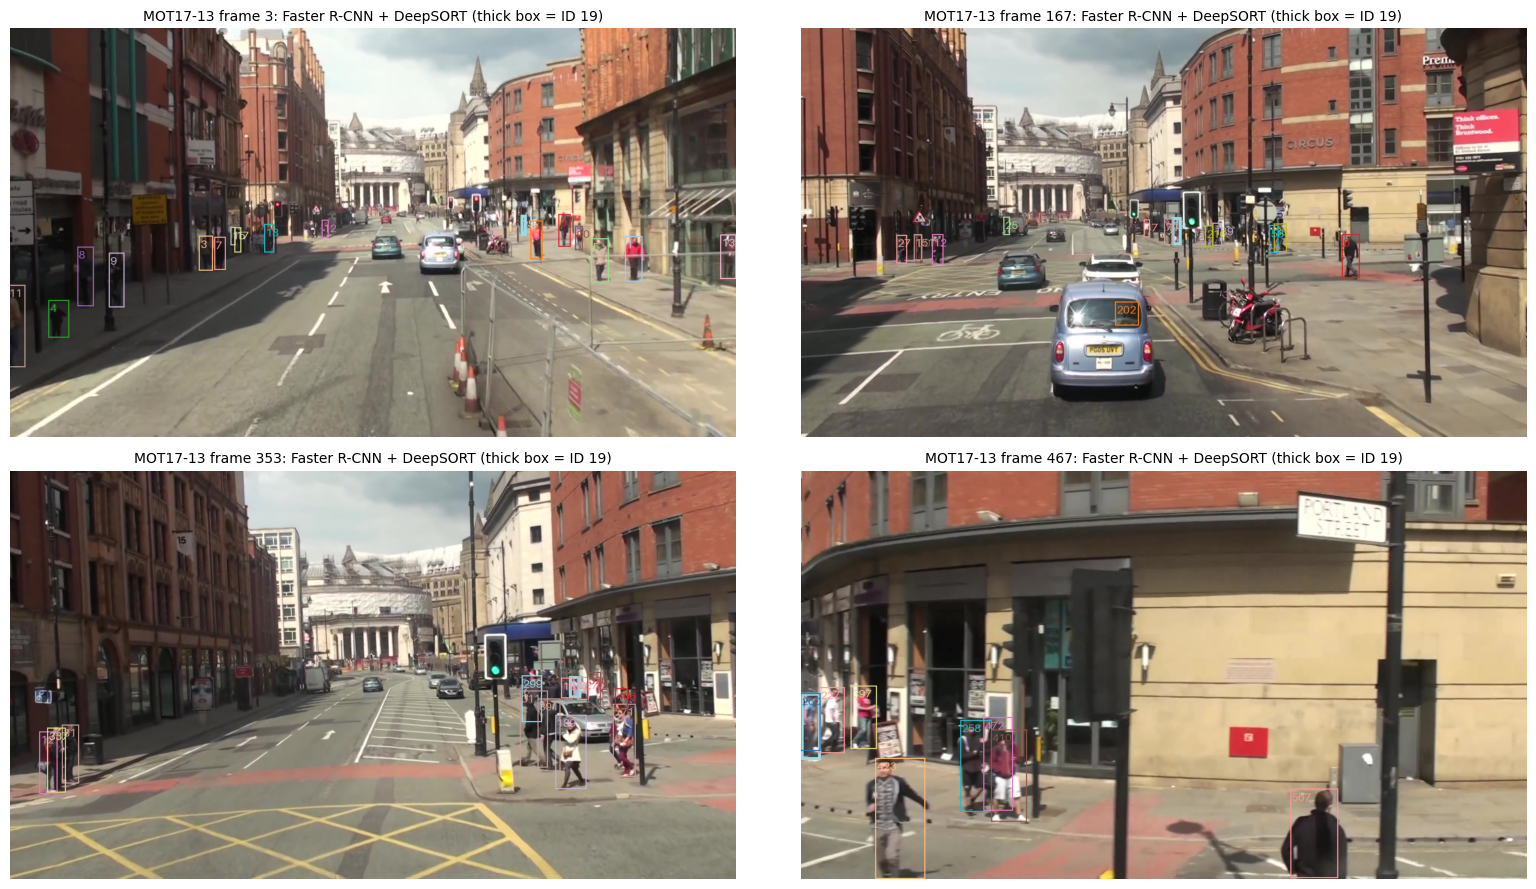

In [19]:
# 6. Visual check: 4 frames of MOT17-13 (the baseline), spread across the life of its longest-lived track,
#    so the same person keeping the same ID can be seen. Every track is drawn; the long-lived one is thicker.
VIS_VIDEO = "MOT17-13"
tracks_a = read_tracks(tracker_file("frcnn", VIS_VIDEO))
lifetime = tracks_a.groupby("id")["frame"].agg(["min", "max", "size"])
lifetime["span"] = lifetime["max"] - lifetime["min"]
focus_id = int(lifetime["span"].idxmax())
focus_frames = tracks_a.loc[tracks_a["id"] == focus_id, "frame"].to_numpy()
picks = [int(focus_frames[i]) for i in np.linspace(0, len(focus_frames) - 1, 4).round().astype(int)]
print(f"Longest-lived track: ID {focus_id}, frames {lifetime.loc[focus_id, 'min']}-{lifetime.loc[focus_id, 'max']} "
      f"({lifetime.loc[focus_id, 'size']} frames written). Frames drawn: {picks}")

font = ImageFont.load_default(size=30)
saved = []
for frame in picks:
    image = open_original(FRAMES_OF[VIS_VIDEO].set_index("frame").loc[frame, "image_path"])
    draw = ImageDraw.Draw(image)
    for t in tracks_a[tracks_a["frame"] == frame].itertuples():
        colour = tuple(int(255 * c) for c in plt.cm.tab20(t.id % 20)[:3])    # same colour for the same ID
        draw.rectangle([t.left, t.top, t.left + t.width, t.top + t.height], outline=colour,
                       width=8 if t.id == focus_id else 3)
        draw.text((t.left + 4, t.top + 2), str(t.id), fill=colour, font=font)
    path = DS_OUT / "figures" / f"baseline_{VIS_VIDEO}_frame{frame:06d}.jpg"
    image.save(path, quality=90)
    saved.append((frame, image))
check("visual check figures saved", len(saved) == 4, f"{len(saved)} frames in {DS_OUT / 'figures'}, following ID {focus_id}")

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, (frame, image) in zip(axes.flat, saved):
    ax.imshow(image)
    ax.set_title(f"{VIS_VIDEO} frame {frame}: Faster R-CNN + DeepSORT (thick box = ID {focus_id})", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Summary

In [20]:
# Add the checks to the report and print the results table.
checks_table = pd.DataFrame(check_results)
report["Checks"] = (f"{checks_table['passed'].sum()} of {len(checks_table)} checks passed.\n\n"
                    + md_table(checks_table))
write_report()

print(f"Checks passed: {checks_table['passed'].sum()} / {len(checks_table)}")
for row in checks_table[~checks_table["passed"]].itertuples():
    print("  FAILED:", row.check, "-", row.detail)
print()
print("Baseline results: our Faster R-CNN (COCO) + DeepSORT (HOTA, MOTA, IDF1 in %):")
print(results.round(2).to_string(index=False))
print()
print(detector_quality.round(1).to_string(index=False))

Checks passed: 11 / 11

Baseline results: our Faster R-CNN (COCO) + DeepSORT (HOTA, MOTA, IDF1 in %):
source    video  HOTA  MOTA  IDF1  ID_switches  false_positives  false_negatives  detections  detector_fps  tracker_fps  end_to_end_fps data_version
 frcnn MOT17-10 36.62 33.68 43.92          256             3943             4316       13038          0.96         4.06            0.77   4b5c066475
 frcnn MOT17-13 39.54 34.37 50.60          177             2587             4877        9629          0.97         6.18            0.84   4b5c066475

   video  gt_boxes  detections  matched  recall_pct  precision_pct_lower_bound
MOT17-10     12839       13038     8363        65.1                       64.1
MOT17-13     11642        9629     6832        58.7                       71.0
